<a href="https://colab.research.google.com/github/wani0502/Machine-Learning-Algorithms/blob/main/qnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
from google.colab import files
import os
import zipfile

uploaded = files.upload()

zip_files = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]

if not zip_files:
    raise ValueError("Please upload your MNIST ZIP file.")

zip_path = "/content/" + zip_files[0]
extract_dir = "/content/mnist"

os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

print("ZIP extracted successfully!")
print("Files:", os.listdir(extract_dir))


Saving archive.zip to archive (1).zip
ZIP extracted successfully!
Files: ['t10k-images.idx3-ubyte', 't10k-labels.idx1-ubyte', 'train-labels.idx1-ubyte', 'train-images.idx3-ubyte']


In [8]:

import os

def find_file(filename):
    for root, dirs, files_list in os.walk("/content/mnist"):
        if filename in files_list:
            return os.path.join(root, filename)

    raise FileNotFoundError(
        f"{filename} not found inside the extracted dataset."
    )

train_images_path = find_file("train-images.idx3-ubyte")
train_labels_path = find_file("train-labels.idx1-ubyte")
test_images_path = find_file("t10k-images.idx3-ubyte")
test_labels_path = find_file("t10k-labels.idx1-ubyte")

print("All four MNIST files found!")
print(train_images_path)
print(train_labels_path)
print(test_images_path)
print(test_labels_path)


All four MNIST files found!
/content/mnist/train-images.idx3-ubyte
/content/mnist/train-labels.idx1-ubyte
/content/mnist/t10k-images.idx3-ubyte
/content/mnist/t10k-labels.idx1-ubyte


In [9]:

import numpy as np
import struct

def load_images(path):
    with open(path, "rb") as f:
        magic, n, rows, cols = struct.unpack(
            ">IIII", f.read(16)
        )
        assert magic == 2051, "Invalid MNIST image file"

        data = np.frombuffer(f.read(), dtype=np.uint8)
        return data.reshape(n, rows, cols).copy()

def load_labels(path):
    with open(path, "rb") as f:
        magic, n = struct.unpack(">II", f.read(8))
        assert magic == 2049, "Invalid MNIST label file"

        data = np.frombuffer(f.read(), dtype=np.uint8)
        return data.copy()

X_train = load_images(train_images_path)
y_train = load_labels(train_labels_path)

X_test = load_images(test_images_path)
y_test = load_labels(test_labels_path)

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)


Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


In [10]:

train_mask = np.isin(y_train, [3, 6])
test_mask = np.isin(y_test, [3, 6])

X_train_36 = X_train[train_mask]
y_train_36 = (y_train[train_mask] == 3).astype(np.int8)

X_test_36 = X_test[test_mask]
y_test_36 = (y_test[test_mask] == 3).astype(np.int8)

print("Filtered training:", X_train_36.shape)
print("Filtered testing:", X_test_36.shape)

print("Training counts (0=digit 6, 1=digit 3):",
      np.unique(y_train_36, return_counts=True))
print("Testing counts (0=digit 6, 1=digit 3):",
      np.unique(y_test_36, return_counts=True))


Filtered training: (12049, 28, 28)
Filtered testing: (1968, 28, 28)
Training counts (0=digit 6, 1=digit 3): (array([0, 1], dtype=int8), array([5918, 6131]))
Testing counts (0=digit 6, 1=digit 3): (array([0, 1], dtype=int8), array([ 958, 1010]))


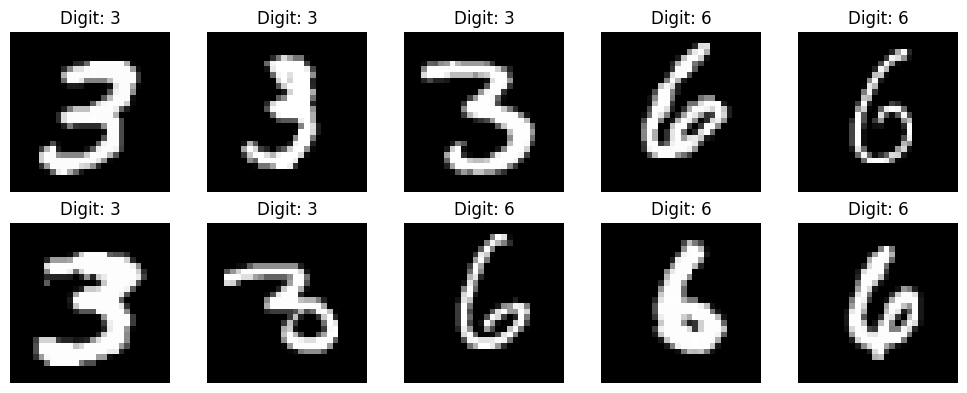

In [11]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_train_36[i], cmap="gray")
    digit = 3 if y_train_36[i] == 1 else 6
    ax.set_title(f"Digit: {digit}")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [12]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

def resize_images(images):
    resized = []

    for img in images:
        pil_img = Image.fromarray(img)
        small_img = pil_img.resize(
            (4, 4), Image.Resampling.BOX
        )
        resized.append(np.array(small_img))

    return np.array(resized, dtype=np.uint8)

X_train_small = resize_images(X_train_36)
X_test_small = resize_images(X_test_36)

print("Resized training:", X_train_small.shape)
print("Resized testing:", X_test_small.shape)


Resized training: (12049, 4, 4)
Resized testing: (1968, 4, 4)


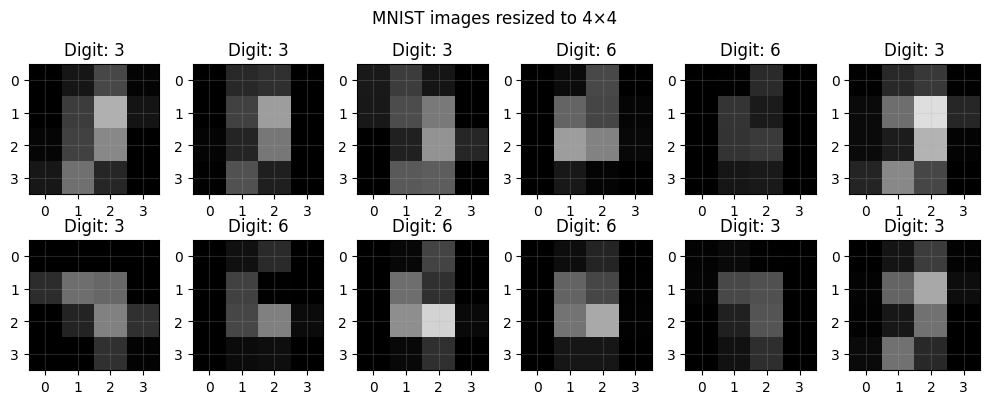

In [13]:
fig, axes = plt.subplots(2, 6, figsize=(10, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_train_small[i], cmap="gray", vmin=0, vmax=255)
    digit = 3 if y_train_36[i] == 1 else 6
    ax.set_title(f"Digit: {digit}")
    ax.set_xticks(range(4))
    ax.set_yticks(range(4))
    ax.grid(alpha=0.2)

plt.suptitle("MNIST images resized to 4×4")
plt.tight_layout()
plt.show()


In [14]:
THRESHOLD = 0.5

X_train_bin = (
    X_train_small.astype(np.float32) / 255.0 > THRESHOLD
).astype(np.uint8)

X_test_bin = (
    X_test_small.astype(np.float32) / 255.0 > THRESHOLD
).astype(np.uint8)

print("Binary training shape:", X_train_bin.shape)
print("Binary testing shape:", X_test_bin.shape)
print("Unique pixel values:", np.unique(X_train_bin))


Binary training shape: (12049, 4, 4)
Binary testing shape: (1968, 4, 4)
Unique pixel values: [0 1]


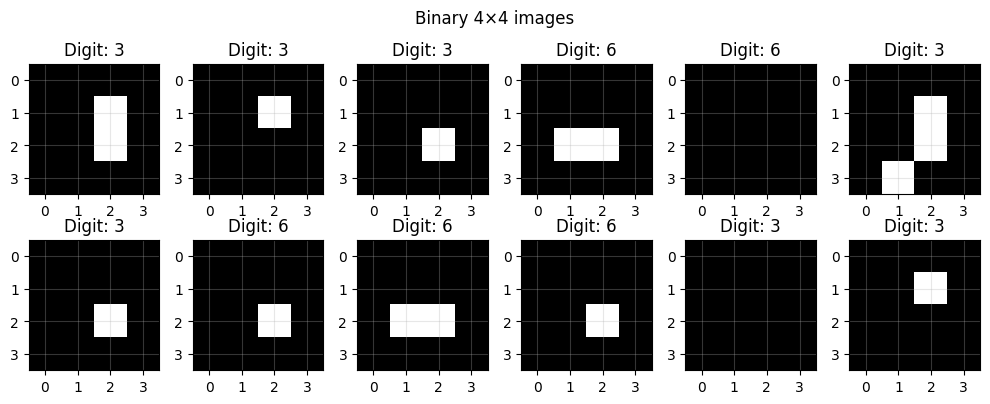

In [15]:
fig, axes = plt.subplots(2, 6, figsize=(10, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_train_bin[i], cmap="gray", vmin=0, vmax=1)
    digit = 3 if y_train_36[i] == 1 else 6
    ax.set_title(f"Digit: {digit}")
    ax.set_xticks(range(4))
    ax.set_yticks(range(4))
    ax.grid(alpha=0.3)

plt.suptitle("Binary 4×4 images")
plt.tight_layout()
plt.show()


In [16]:
def remove_contradictions(images, labels):
    flat = images.reshape(len(images), -1)

    patterns, inverse = np.unique(
        flat, axis=0, return_inverse=True
    )

    label_masks = np.zeros((len(patterns), 2), dtype=bool)
    np.logical_or.at(
        label_masks, (inverse, labels.astype(int)), True
    )

    contradictory = label_masks.all(axis=1)
    keep = ~contradictory[inverse]

    return images[keep], labels[keep], int(contradictory.sum())

X_train_clean, y_train_clean, train_conflicts = (
    remove_contradictions(X_train_bin, y_train_36)
)

X_test_clean, y_test_clean, test_conflicts = (
    remove_contradictions(X_test_bin, y_test_36)
)

print("Training before:", len(y_train_36))
print("Training after:", len(y_train_clean))
print("Contradictory training patterns:", train_conflicts)

print("Testing before:", len(y_test_36))
print("Testing after:", len(y_test_clean))
print("Contradictory test patterns:", test_conflicts)


Training before: 12049
Training after: 420
Contradictory training patterns: 13
Testing before: 1968
Testing after: 445
Contradictory test patterns: 10


In [17]:
%pip install -q qiskit qiskit-aer


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 61.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 78.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 60.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.2 MB/s eta 0:00:00


In [20]:

%pip install -q matplotlib pylatexenc


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 2.2 MB/s eta 0:00:00


In [22]:
from qiskit import QuantumCircuit

def image_to_circuit(image):
    pixels = np.asarray(image).reshape(-1)

    # 16 data qubits + 1 readout qubit
    qc = QuantumCircuit(17)

    # Binary pixel encoding
    for i, pixel in enumerate(pixels):
        if pixel == 1:
            qc.x(i)

    return qc

example_circuit = image_to_circuit(X_train_clean[0])

print("Number of qubits:", example_circuit.num_qubits)
print("Number of operations:", example_circuit.size())

example_circuit.draw("mpl")


Number of qubits: 17
Number of operations: 3


MissingOptionalLibraryError: "The 'pylatexenc' library is required to use 'MatplotlibDrawer'. You can install it with 'pip install pylatexenc'."

In [23]:

print("Qubits:", example_circuit.num_qubits)
print("Operations:", example_circuit.size())

print(example_circuit.draw(output="text"))


Qubits: 17
Operations: 3
           
 q_0: ─────
           
 q_1: ─────
           
 q_2: ─────
           
 q_3: ─────
           
 q_4: ─────
           
 q_5: ─────
      ┌───┐
 q_6: ┤ X ├
      └───┘
 q_7: ─────
           
 q_8: ─────
           
 q_9: ─────
      ┌───┐
q_10: ┤ X ├
      └───┘
q_11: ─────
           
q_12: ─────
      ┌───┐
q_13: ┤ X ├
      └───┘
q_14: ─────
           
q_15: ─────
           
q_16: ─────
           


In [24]:

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector

N_DATA = 16
N_QUBITS = 17
N_LAYERS = 2

theta = ParameterVector("theta", N_LAYERS * N_QUBITS)

def build_qnn_circuit():
    qc = QuantumCircuit(N_QUBITS)

    # Read binary image into the data qubits
    for i in range(N_DATA):
        qc.h(i)

    # Trainable layers
    k = 0
    for layer in range(N_LAYERS):
        for q in range(N_QUBITS):
            qc.ry(theta[k], q)
            k += 1

        # Entangle neighboring qubits
        for q in range(N_QUBITS - 1):
            qc.cx(q, q + 1)

    # Measure the readout qubit
    qc.h(16)
    qc.measure_all()

    return qc

qnn_circuit = build_qnn_circuit()

print("Qubits:", qnn_circuit.num_qubits)
print("Trainable parameters:", len(theta))
print("Circuit operations:", qnn_circuit.size())
print(qnn_circuit.draw(output="text"))


Qubits: 17
Trainable parameters: 34
Circuit operations: 100
               ┌───┐       ┌──────────────┐     ┌───────────────┐»
    q_0: ──────┤ H ├───────┤ Ry(theta[0]) ├──■──┤ Ry(theta[17]) ├»
               ├───┤       ├──────────────┤┌─┴─┐└───────────────┘»
    q_1: ──────┤ H ├───────┤ Ry(theta[1]) ├┤ X ├────────■────────»
               ├───┤       ├──────────────┤└───┘      ┌─┴─┐      »
    q_2: ──────┤ H ├───────┤ Ry(theta[2]) ├───────────┤ X ├──────»
               ├───┤       ├──────────────┤           └───┘      »
    q_3: ──────┤ H ├───────┤ Ry(theta[3]) ├──────────────────────»
               ├───┤       ├──────────────┤                      »
    q_4: ──────┤ H ├───────┤ Ry(theta[4]) ├──────────────────────»
               ├───┤       ├──────────────┤                      »
    q_5: ──────┤ H ├───────┤ Ry(theta[5]) ├──────────────────────»
               ├───┤       ├──────────────┤                      »
    q_6: ──────┤ H ├───────┤ Ry(theta[6]) ├──────────────────────»
  

In [25]:

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
import numpy as np

N_DATA = 16
N_QUBITS = 17
N_LAYERS = 2

theta = ParameterVector("theta", N_QUBITS * N_LAYERS)

def build_qnn_circuit(image):
    pixels = np.asarray(image, dtype=np.uint8).reshape(-1)

    if len(pixels) != 16:
        raise ValueError("Expected a 4x4 binary image")

    qc = QuantumCircuit(17, 1)

    # Encode the image
    for i, pixel in enumerate(pixels):
        if pixel == 1:
            qc.x(i)

    # Trainable layers
    k = 0
    for _ in range(N_LAYERS):
        for q in range(N_QUBITS):
            qc.ry(theta[k], q)
            k += 1

        for q in range(N_QUBITS - 1):
            qc.cx(q, q + 1)

    # Measure only the readout qubit
    qc.h(16)
    qc.measure(16, 0)

    return qc

example_qnn = build_qnn_circuit(X_train_clean[0])

print("Qubits:", example_qnn.num_qubits)
print("Classical bits:", example_qnn.num_clbits)
print("Parameters:", len(example_qnn.parameters))


Qubits: 17
Classical bits: 1
Parameters: 34


In [26]:

from qiskit_aer import AerSimulator

simulator = AerSimulator()

rng = np.random.default_rng(42)
initial_values = rng.uniform(
    -np.pi, np.pi, len(theta)
)

parameter_map = {
    theta[i]: initial_values[i]
    for i in range(len(theta))
}

print("Simulator initialized.")
print("Parameters initialized:", len(parameter_map))


Simulator initialized.
Parameters initialized: 34


In [27]:

bound_circuit = example_qnn.assign_parameters(parameter_map)

result = simulator.run(
    bound_circuit,
    shots=1024
).result()

counts = result.get_counts()
total = sum(counts.values())

p_one = counts.get("1", 0) / total
p_zero = counts.get("0", 0) / total

expectation = p_zero - p_one

print("Measurement counts:", counts)
print("Probability of 0:", p_zero)
print("Probability of 1:", p_one)
print("Readout expectation:", expectation)


Measurement counts: {'1': 377, '0': 647}
Probability of 0: 0.6318359375
Probability of 1: 0.3681640625
Readout expectation: 0.263671875


In [28]:

for i in range(5):
    circuit = build_qnn_circuit(X_train_clean[i])
    bound = circuit.assign_parameters(parameter_map)

    result = simulator.run(
        bound, shots=512
    ).result()

    counts = result.get_counts()
    total = sum(counts.values())

    p_one = counts.get("1", 0) / total
    score = 1 - 2 * p_one

    actual_digit = 3 if y_train_clean[i] == 1 else 6

    print(
        f"Image {i}: actual={actual_digit}, "
        f"readout score={score:.3f}"
    )


Image 0: actual=3, readout score=0.297
Image 1: actual=3, readout score=0.219
Image 2: actual=3, readout score=0.250
Image 3: actual=6, readout score=0.293
Image 4: actual=3, readout score=0.156


In [30]:

import numpy as np

# Flatten the cleaned images
X_pool = X_train_clean.reshape(len(X_train_clean), 16)
y_pool = y_train_clean.astype(np.float32)

# Reproducible, stratified split without scikit-learn
rng = np.random.default_rng(42)

idx_0 = np.where(y_pool == 0)[0]
idx_1 = np.where(y_pool == 1)[0]

rng.shuffle(idx_0)
rng.shuffle(idx_1)

train_idx = np.concatenate([idx_0[:50], idx_1[:50]])
val_idx = np.concatenate([idx_0[50:70], idx_1[50:70]])

rng.shuffle(train_idx)
rng.shuffle(val_idx)

X_train_qnn = X_pool[train_idx]
y_train_qnn = y_pool[train_idx]

X_val_qnn = X_pool[val_idx]
y_val_qnn = y_pool[val_idx]

print("Training:", X_train_qnn.shape)
print("Validation:", X_val_qnn.shape)
print("Training labels:", np.unique(
    y_train_qnn, return_counts=True
))


Training: (100, 16)
Validation: (40, 16)
Training labels: (array([0., 1.], dtype=float32), array([50, 50]))


In [31]:

def predict_score(image, parameter_values, shots=256):
    circuit = build_qnn_circuit(image.reshape(4, 4))

    binding = {
        theta[i]: float(parameter_values[i])
        for i in range(len(theta))
    }

    bound = circuit.assign_parameters(binding)

    result = simulator.run(
        bound, shots=shots
    ).result()

    counts = result.get_counts()
    total = sum(counts.values())

    p_one = counts.get("1", 0) / total
    return 1 - 2 * p_one


def predict_class(image, parameter_values):
    return int(predict_score(image, parameter_values) > 0)

print("Prediction functions ready.")


Prediction functions ready.


In [32]:

def hinge_loss(parameter_values, X, y, shots=256):
    signed_labels = 2 * y - 1

    scores = np.array([
        predict_score(x, parameter_values, shots)
        for x in X
    ])

    return np.mean(
        np.maximum(0, 1 - signed_labels * scores)
    )

initial_loss = hinge_loss(
    initial_values,
    X_train_qnn[:5],
    y_train_qnn[:5]
)

print("Initial hinge loss:", initial_loss)


Initial hinge loss: 1.1234375


In [33]:

import scipy
print("SciPy version:", scipy.__version__)


SciPy version: 1.16.3


Epoch 01/15 | Loss: 1.0016
Epoch 02/15 | Loss: 0.9805
Epoch 03/15 | Loss: 0.9789
Epoch 04/15 | Loss: 1.0414
Epoch 05/15 | Loss: 0.9992
Epoch 06/15 | Loss: 0.9766
Epoch 07/15 | Loss: 0.9867
Epoch 08/15 | Loss: 0.9953
Epoch 09/15 | Loss: 1.0125
Epoch 10/15 | Loss: 1.0109
Epoch 11/15 | Loss: 0.9883
Epoch 12/15 | Loss: 0.9805
Epoch 13/15 | Loss: 1.0133
Epoch 14/15 | Loss: 0.9953
Epoch 15/15 | Loss: 0.9891


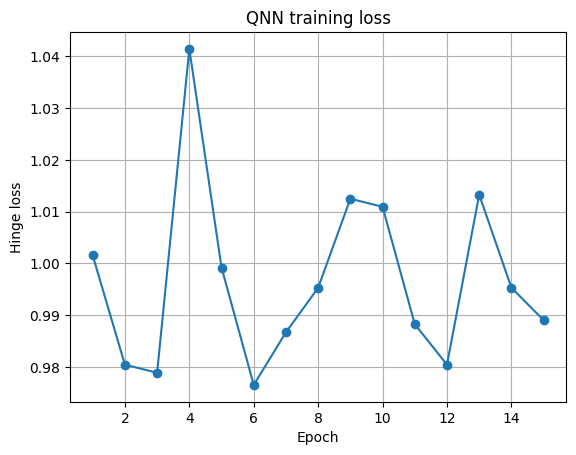

In [34]:

import numpy as np
import matplotlib.pyplot as plt

# Keep the first experiment small
X_fit = X_train_qnn[:10]
y_fit = y_train_qnn[:10]

params = initial_values.copy()

epochs = 15
a = 0.08
c = 0.10
alpha = 0.602
gamma = 0.101

loss_history = []

def objective(p):
    return hinge_loss(p, X_fit, y_fit, shots=256)

for epoch in range(epochs):
    ak = a / ((epoch + 1) ** alpha)
    ck = c / ((epoch + 1) ** gamma)

    delta = np.random.choice([-1.0, 1.0], size=len(params))

    loss_plus = objective(params + ck * delta)
    loss_minus = objective(params - ck * delta)

    gradient_estimate = (
        (loss_plus - loss_minus) / (2 * ck)
    ) * delta

    params -= ak * gradient_estimate

    current_loss = objective(params)
    loss_history.append(current_loss)

    print(
        f"Epoch {epoch + 1:02d}/{epochs} | "
        f"Loss: {current_loss:.4f}"
    )

plt.plot(range(1, epochs + 1), loss_history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Hinge loss")
plt.title("QNN training loss")
plt.grid(True)
plt.show()


In [35]:

trained_loss = hinge_loss(
    params,
    X_train_qnn[:5],
    y_train_qnn[:5],
    shots=256
)

print(f"Initial loss: {initial_loss:.4f}")
print(f"Loss after training: {trained_loss:.4f}")

if trained_loss < initial_loss:
    print("Loss decreased on this comparison subset.")
else:
    print("Loss did not decrease on this comparison subset.")


Initial loss: 1.1234
Loss after training: 1.1062
Loss decreased on this comparison subset.


In [36]:

from collections import Counter

def evaluate_qnn(X, y, parameter_values, shots=512):
    scores = np.array([
        predict_score(x, parameter_values, shots)
        for x in X
    ])

    predictions = (scores > 0).astype(int)
    accuracy = np.mean(predictions == y)

    return scores, predictions, accuracy

val_scores, val_predictions, val_accuracy = evaluate_qnn(
    X_val_qnn,
    y_val_qnn,
    params,
    shots=512
)

print(f"Validation accuracy: {val_accuracy:.4f}")
print(f"Validation accuracy (%): {val_accuracy * 100:.2f}%")
print("Predicted labels (0=6, 1=3):",
      Counter(val_predictions))
print("Actual labels (0=6, 1=3):",
      Counter(y_val_qnn.astype(int)))


Validation accuracy: 0.5000
Validation accuracy (%): 50.00%
Predicted labels (0=6, 1=3): Counter({np.int64(1): 40})
Actual labels (0=6, 1=3): Counter({np.int64(0): 20, np.int64(1): 20})


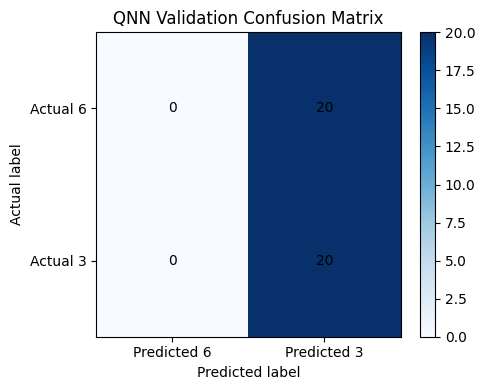

Confusion matrix:
[[ 0 20]
 [ 0 20]]


In [37]:

import matplotlib.pyplot as plt
import numpy as np

cm = np.zeros((2, 2), dtype=int)

for actual, predicted in zip(
    y_val_qnn.astype(int), val_predictions
):
    cm[actual, predicted] += 1

plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap="Blues")
plt.colorbar()

plt.xticks([0, 1], ["Predicted 6", "Predicted 3"])
plt.yticks([0, 1], ["Actual 6", "Actual 3"])
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("QNN Validation Confusion Matrix")

for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]),
                 ha="center", va="center")

plt.tight_layout()
plt.show()

print("Confusion matrix:")
print(cm)


In [38]:

# Inspect score distributions for each class
for label, digit in [(0, 6), (1, 3)]:
    subset = X_val_qnn[y_val_qnn == label]

    scores = np.array([
        predict_score(x, params, shots=1024)
        for x in subset
    ])

    print(f"\nDigit {digit}:")
    print("Mean score:", round(scores.mean(), 4))
    print("Minimum:", round(scores.min(), 4))
    print("Maximum:", round(scores.max(), 4))
    print("Positive scores:", int(np.sum(scores > 0)))



Digit 6:
Mean score: 0.223
Minimum: 0.1816
Maximum: 0.2637
Positive scores: 20

Digit 3:
Mean score: 0.2228
Minimum: 0.1699
Maximum: 0.2793
Positive scores: 20


In [39]:

train_scores = np.array([
    predict_score(x, params, shots=1024)
    for x in X_fit
])

print("Training score range:",
      train_scores.min(), train_scores.max())

print("Training predictions:",
      np.unique((train_scores > 0).astype(int),
                return_counts=True))

print("Training labels:",
      np.unique(y_fit.astype(int), return_counts=True))


Training score range: 0.169921875 0.265625
Training predictions: (array([1]), array([10]))
Training labels: (array([0, 1]), array([5, 5]))
